In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
from sklearn.datasets import fetch_california_housing
california = fetch_california_housing()

In [ ]:
type(california)

sklearn.utils._bunch.Bunch

In [ ]:
california.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'feature_names', 'DESCR'])

In [ ]:
print(type(california.data), type(california.target))

<class 'numpy.ndarray'> <class 'numpy.ndarray'>


In [ ]:
print(california.data.shape, california.target.shape)

(20640, 8) (20640,)


In [ ]:
data = pd.DataFrame(california.data, columns = california.feature_names)
data['Price'] = california.target
data.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
data.describe().round(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


In [ ]:
y = data['Price']
X = data.drop('Price', axis=1)

In [ ]:
y.head()

,Price
0,4.526
1,3.585
2,3.521
3,3.413
4,3.422


In [ ]:
X.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [ ]:
y.shape, X.shape

((20640,), (20640, 8))

In [ ]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X, y)

LinearRegression()

In [ ]:
print("Coefficients: \n", model.coef_)

Coefficients: 
 [ 4.36693293e-01  9.43577803e-03 -1.07322041e-01  6.45065694e-01
 -3.97638942e-06 -3.78654265e-03 -4.21314378e-01 -4.34513755e-01]


In [ ]:
_ = [print(k, v) for k, v in zip(X.columns, model.coef_)]

MedInc 0.4366932931343245
HouseAge 0.009435778033237972
AveRooms -0.10732204139090447
AveBedrms 0.645065693519812
Population -3.976389421211576e-06
AveOccup -0.003786542654971
Latitude -0.42131437752714385
Longitude -0.43451375467477743


In [ ]:
print("Intercept: \n", model.intercept_)

Intercept: 
 -36.94192020718441


In [ ]:
y_pred = model.predict(X)
print(y_pred[:5])

[4.13164983 3.97660644 3.67657094 3.2415985  2.41358744]


In [ ]:
print(y[:5])

0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: Price, dtype: float64


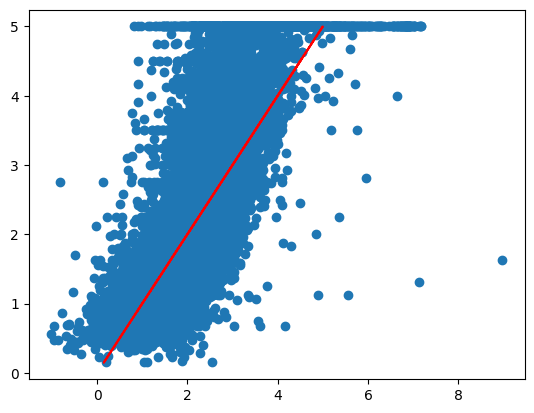

In [ ]:
plt.scatter(y_pred, y)
plt.plot(y, y, c='r')

In [ ]:
model.score(X, y)

0.606232685199805

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(5).fit_transform(X)

In [ ]:
polynomial = LinearRegression()
polynomial.fit(poly, y)
y_pred_poly = polynomial.predict(poly)

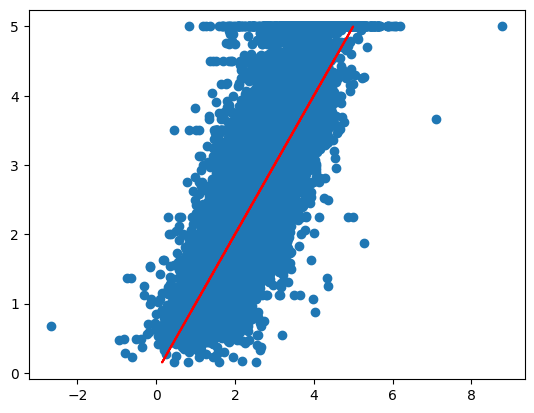

In [ ]:
plt.scatter(y_pred_poly, y)
plt.plot(y, y, c='r')

In [ ]:
polynomial.score(poly, y)

0.7374142530766301

Обучение линейной регрессии своими руками без нормализации


In [ ]:
X.head()

,0,1,2,3,4
0,0.071841,0.855352,-0.305597,0.028253,1.826895
1,0.139521,-0.423507,0.461059,-0.447400,-0.034988
2,1.626311,-0.257622,-0.697520,1.413219,1.086292
3,-1.183233,-0.826343,0.073047,-0.639690,-0.503273
4,-0.783365,-0.861232,0.951448,-0.117306,0.680597


In [ ]:
y.head()

,0
0,63.320498
1,-23.426394
2,11.982771
3,-102.883304
4,-49.373475


In [ ]:
X.shape, y.shape

((20640, 8), (20640,))

In [ ]:
class MultipleRegression(object):
    def __init__(self):
        self.b = None
    def predict(self, x):
        return X @ self.b
    def MSE(self, X, y):
        return (((y - self.predict(x)).T @ (y - self.predict(x))) / (2 * X.shape[0])).values
    def MAE(self, x, y):
        return (abs(y - self.predict(X)).mean()).values
    def MAPE(self, x, y):
        return (abs((y - self.predict(X))/y).mean()).values
    def coefs(self):
        return self.b
    def fit(self, X, y, alpha = 10^(-8), accuracy = 0.1, max_steps = 10000, intercept = True):
        y = np.array(y).reshape(-1, 1)
        if intercept:
            x['intercept'] = 1
        self.b = np.zeros((X.shape[1], 1))
        steps, errors = [], []
        step = 0
        for _ in range(max_steps):
            dJ_b = X.T @ (self.predict(X) - y) / X.shape[0]
            self.b -= alpha * dJ_b
            new_error = self.MSE(X, y)
            step += 1
            steps.append(step)
            errors.append(new_error)
        return steps, errors

In [ ]:
regr = MultipleRegression()
x_ = X.copy()
steps, errors = regr.fit(X, y, alpha = 1e-8, accuracy = 0.01, max_steps = 1000, intercept = True)

ValueError: matrices are not aligned

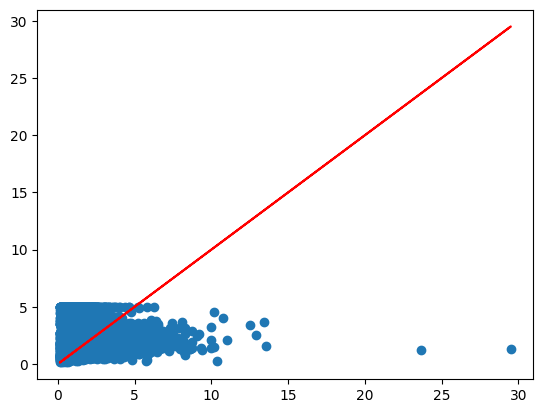

In [ ]:
yy = regr.predict(x)
plt.scatter(yy, y)
plt.plot(yy, yy, c='r')

In [ ]:
print(regr.MAE(x, y)) # средняя абсолютная ошибка

KeyboardInterrupt: 

In [ ]:
print(regr.MSE(x, y)) # среднее квадратичное отколонение

In [ ]:
regr.MAPE(x, y) # средняя абсолютная процентная погрешность

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error

In [ ]:
r2_score(y, regr.predict(x))
mean_squared_error(y, regr.predict(x))

2.825058579456639

Оценка множественной регрессии


In [ ]:
x.shape, y.shape

((387, 6), (387, 1))

In [ ]:
type(x), type(y)

(pandas.core.frame.DataFrame, pandas.core.frame.DataFrame)

In [ ]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x, y)

TypeError: Feature names are only supported if all input features have string names, but your input has ['int', 'str'] as feature name / column name types. If you want feature names to be stored and validated, you must convert them all to strings, by using X.columns = X.columns.astype(str) for example. Otherwise you can remove feature / column names from your input data, or convert them all to a non-string data type.

In [ ]:
print("Coefficients: \n", model.coef_)

Coefficients: 
 [[15.79537523 93.21521093 37.19410687 31.19129121 -0.23773114]]


In [ ]:
_ = [print(k, v) for k, v in zip(X.columns, model.coef_)]

MedInc [15.79537523 93.21521093 37.19410687 31.19129121 -0.23773114]


In [ ]:
print("Intercept: \n", model.intercept_)

Intercept: 
 [0.56498354]


In [ ]:
y_pred = model.predict(x)
print(y_pred[:5])

[[  70.51212888]
 [ -33.50647619]
 [  20.1171874 ]
 [-112.26853902]
 [ -60.52096787]]


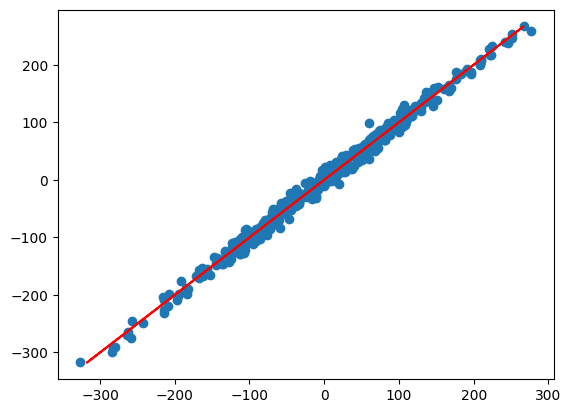

In [ ]:
plt.scatter(y_pred, y)
plt.plot(y, y, c='r')

In [ ]:
model.score(x, y) # модель очень точная. Посмотрим, что будет, если сделать через полиномиальную регрессию

0.9922198026415868

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(5).fit_transform(x)

In [ ]:
polynomial = LinearRegression()
polynomial.fit(poly, y)
y_pred_poly = polynomial.predict(poly)

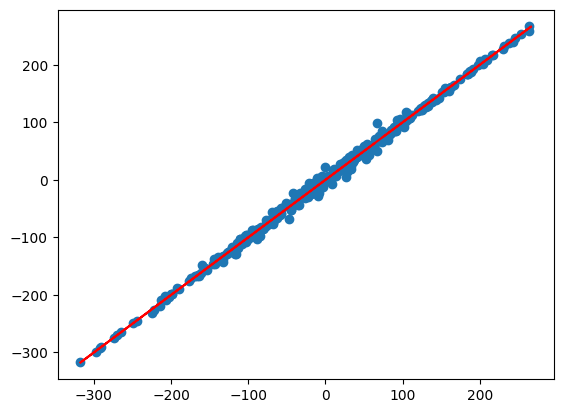

In [ ]:
plt.scatter(y_pred_poly, y)
plt.plot(y, y, c='r')

In [ ]:
polynomial.score(poly, y) #Коэффициент приблизился к 1, а значит модель стала еще точнее

0.9972316448482262

In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

scaler = MinMaxScaler()
x = scaler.fit_transform(x)

In [ ]:
x

array([[0.53966842, 0.78431373, 0.0435123 , ..., 0.5674814 , 0.21115538,
        0.        ],
       [0.53802706, 0.39215686, 0.03822395, ..., 0.565356  , 0.21215139,
        0.        ],
       [0.46602805, 1.        , 0.05275646, ..., 0.5642933 , 0.21015936,
        0.        ],
       ...,
       [0.08276438, 0.31372549, 0.03090386, ..., 0.73219979, 0.31175299,
        0.        ],
       [0.09429525, 0.33333333, 0.03178269, ..., 0.73219979, 0.30179283,
        0.        ],
       [0.13025338, 0.29411765, 0.03125246, ..., 0.72582359, 0.30976096,
        0.        ]])

In [ ]:
x = pd.DataFrame(x)

In [ ]:
x.head()

,0,1,2,3,4,5,6,7,8
0,0.539668,0.784314,0.043512,0.020469,0.008941,0.001499,0.567481,0.211155,0.0
1,0.538027,0.392157,0.038224,0.018929,0.067210,0.001141,0.565356,0.212151,0.0
2,0.466028,1.000000,0.052756,0.021940,0.013818,0.001698,0.564293,0.210159,0.0
3,0.354699,1.000000,0.035241,0.021929,0.015555,0.001493,0.564293,0.209163,0.0
4,0.230776,1.000000,0.038534,0.022166,0.015752,0.001198,0.564293,0.209163,0.0


In [ ]:
class MultipleRegression(object):
    def __init__(self):
        self.b = None
    def predict(self, x):
        return x @ self.b
    def MSE(self, x, y):
        return (((y - self.predict(x)).T @ (y - self.predict(x))) / (2 * x.shape[0])).values
    def MAE(self, x, y):
        return (abs(y - self.predict(x)).mean()).values
    def MAPE(self, x, y):
        return (abs((y - self.predict(x))/y).mean()).values
    def coefs(self):
        return self.b
    def fit(self, x, y, alpha = 0.1, accuracy = 0.1, max_steps = 10000, intercept = True):
        y = np.array(y).reshape(-1, 1)
        if intercept:
            x['intercept'] = 1
        self.b = np.zeros((x.shape[1], 1))
        steps, errors = [], []
        step = 0
        for _ in range(max_steps):
            dJ_b = x.T @ (self.predict(x) - y) / x.shape[0]
            self.b -= alpha * dJ_b
            new_error = self.MSE(x, y)
            step += 1
            steps.append(step)
            errors.append(new_error)
        return steps, errors

In [ ]:
regr = MultipleRegression()
x_ = x.copy()
steps, errors = regr.fit(x, y, alpha = 0.5, accuracy = 0.01, max_steps = 1000, intercept = True)

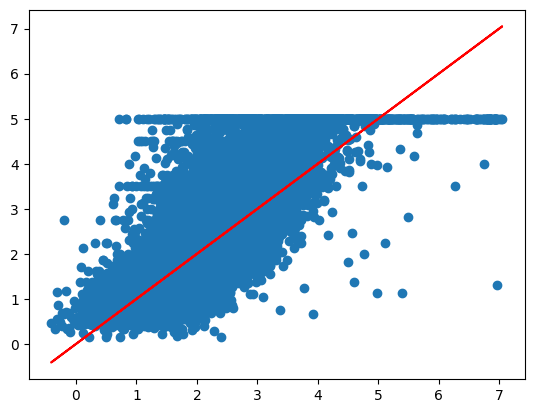

In [ ]:
yy = regr.predict(x)
plt.scatter(yy, y)
plt.plot(yy, yy, c='r')

In [ ]:
x.shape, y.shape

((20640, 10), (20640,))

In [ ]:
x.columns = x.columns.astype(str)

In [ ]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x, y)

LinearRegression()

In [ ]:
print("Coefficients: \n", model.coef_)

Coefficients: 
 [  6.33214009   0.48122468 -15.13916237  21.76021606  -0.1418736
  -4.70531325  -3.96456829  -4.3625181    0.           0.        ]


In [ ]:
_ = [print(k, v) for k, v in zip(x.columns, model.coef_)]

0 6.332140089106333
1 0.48122467969509497
2 -15.139162370191034
3 21.76021606140164
4 -0.14187359815944298
5 -4.705313248406513
6 -3.9645682925304317
7 -4.36251809693479
8 0.0
intercept 0.0


In [ ]:
print("Intercept: \n", model.intercept_)

Intercept: 
 3.729611655126404


In [ ]:
y_pred = model.predict(x)
print(y_pred[:5])

[4.13164983 3.97660644 3.67657094 3.2415985  2.41358744]


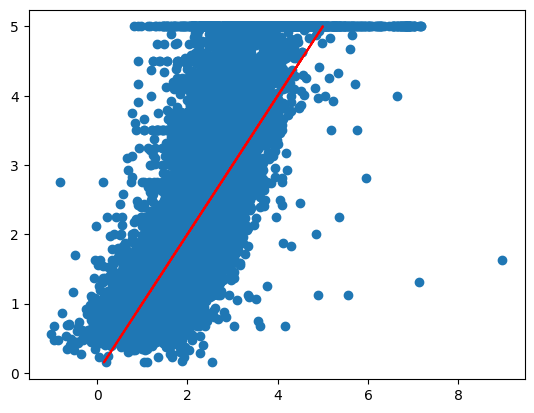

In [ ]:
plt.scatter(y_pred, y)
plt.plot(y, y, c='r')

In [ ]:
model.score(x, y)

0.6062326851998052

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(2).fit_transform(x)

In [ ]:
polynomial = LinearRegression()
polynomial.fit(poly, y)
y_pred_poly = polynomial.predict(poly)

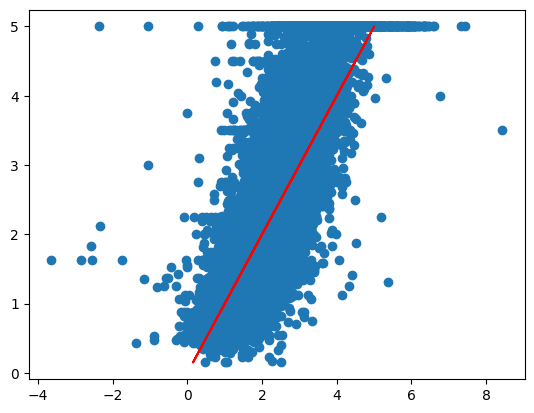

In [ ]:
plt.scatter(y_pred_poly, y)
plt.plot(y, y, c='r')

In [ ]:
polynomial.score(poly, y)

0.6832976293317492

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(3).fit_transform(x)

In [ ]:
polynomial = LinearRegression()
polynomial.fit(poly, y)
y_pred_poly = polynomial.predict(poly)

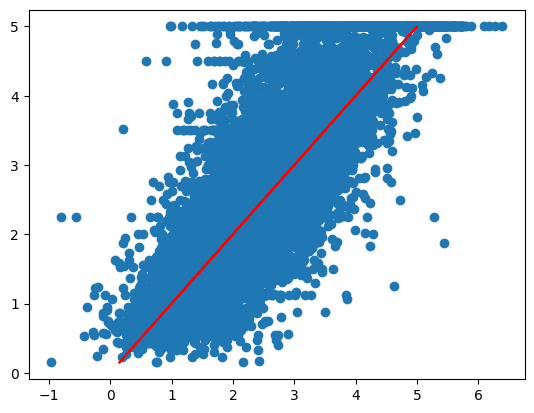

In [ ]:
plt.scatter(y_pred_poly, y)
plt.plot(y, y, c='r')

In [ ]:
polynomial.score(poly, y)

0.7385168108924949

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(4).fit_transform(x)

In [ ]:
polynomial = LinearRegression()
polynomial.fit(poly, y)
y_pred_poly = polynomial.predict(poly)

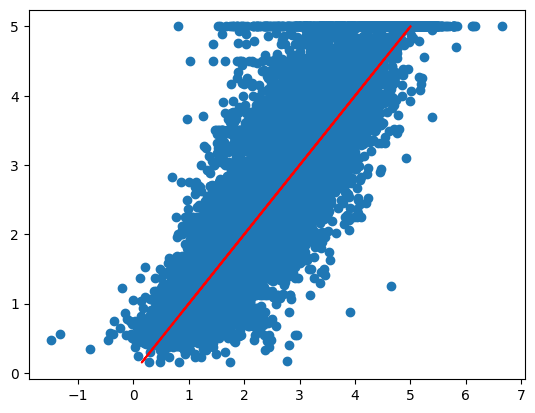

In [ ]:
plt.scatter(y_pred_poly, y)
plt.plot(y, y, c='r')

In [ ]:
polynomial.score(poly, y)

0.7834366976783456